In [1]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 11.1 MB/s eta 0:00:00


In [9]:
!pip install lightgbm

  Using cached lightgbm-4.6.0-py3-none-manylinux_2_28_x86_64.whl.metadata (17 kB)
Using cached lightgbm-4.6.0-py3-none-manylinux_2_28_x86_64.whl (3.6 MB)


In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from lightgbm import LGBMRegressor
import joblib


In [11]:
# Load data
data = pd.read_csv('/../DATA/clean_data.csv')

# Feature configuration
numeric_features = ['year', 'kilometrage', 'puissance', 'Nombre_doors']
categorical_features = ['type_boit', 'type_carburant', 'marke', 'model', 'premiere_main', 'city']



In [13]:
X = data.drop('price', axis=1)
y = data['price']
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)


preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])



In [14]:

model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LGBMRegressor(
        objective='regression',
        num_leaves=31,
        learning_rate=0.05,
        n_estimators=1000,
        random_state=42  
    ))
])


In [15]:


print("Training LightGBM model...")
model.fit(X_train, y_train)


Training LightGBM model...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005300 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 846
[LightGBM] [Info] Number of data points in the train set: 35490, number of used features: 381
[LightGBM] [Info] Start training from score 130907.375289


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['year', 'kilometrage',
                                                   'puissance',
                                                   'Nombre_doors']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type_boit',
                                                   'type_carburant', 'marke',
                                                   'model', 'premiere_main',
                                                   'city'])])),
                ('regressor',
                 LGBMRegressor(learning_rate=0.05, n_estimators=1000,
                               objective='regression', random_state=42))])

In [16]:

def evaluate(model, X_true, y_true, label):
    y_pred = model.predict(X_true)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    print(f"\n--- {label} Set ---")
    print(f"MSE: {mse:,.2f}")
    print(f"RMSE: {rmse:,.2f}")
    print(f"MAE: {mae:,.2f}")
    print(f"R²: {r2:.4f}")

   
    plt.figure(figsize=(12, 5))

    #Prediction VS Actual
    plt.subplot(1, 2, 1)
    sns.regplot(x=y_true, y=y_pred, scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'})
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'k--')
    plt.title(f'{label}: Actual vs Predicted')
    plt.xlabel('Actual Prices')
    plt.ylabel('Predicted Prices')

    # Residual Distribution
    plt.subplot(1, 2, 2)
    sns.histplot(y_true - y_pred, kde=True, color='blue')
    plt.title(f'{label}: Residual Distribution')
    plt.xlabel('Prediction Error')

    plt.tight_layout()
    plt.show()

    return {
        'Model': f'LightGBM ({label})',
        'MSE': f"{mse:,.2f}",
        'RMSE': f"{rmse:,.2f}",
        'MAE': f"{mae:,.2f}",
        'R²': f"{r2:.4f}"
    }


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



--- Validation Set ---
MSE: 650,223,593.96
RMSE: 25,499.48
MAE: 14,962.06
R²: 0.9111


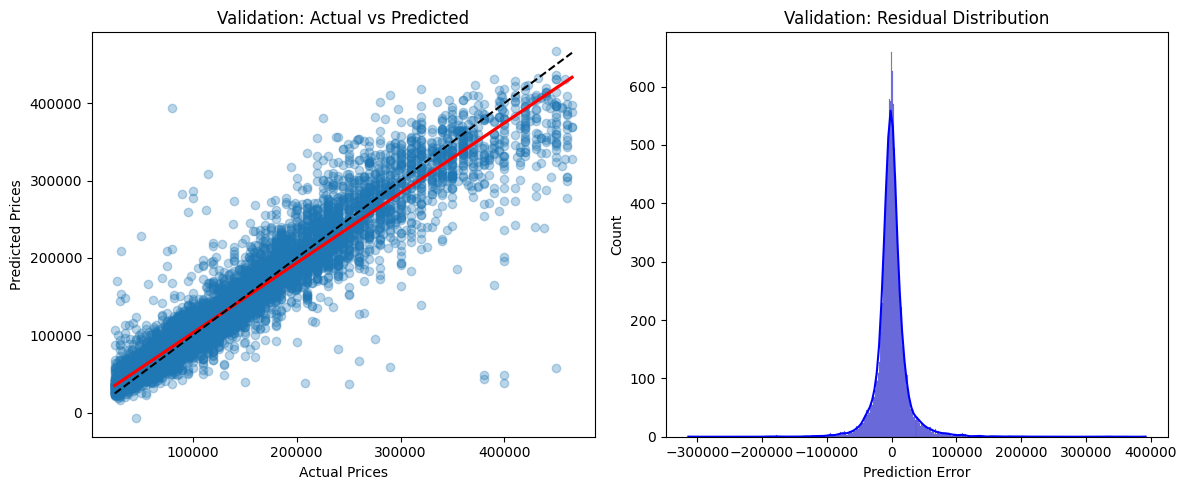

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



--- Test Set ---
MSE: 666,973,684.59
RMSE: 25,825.83
MAE: 14,943.63
R²: 0.9068


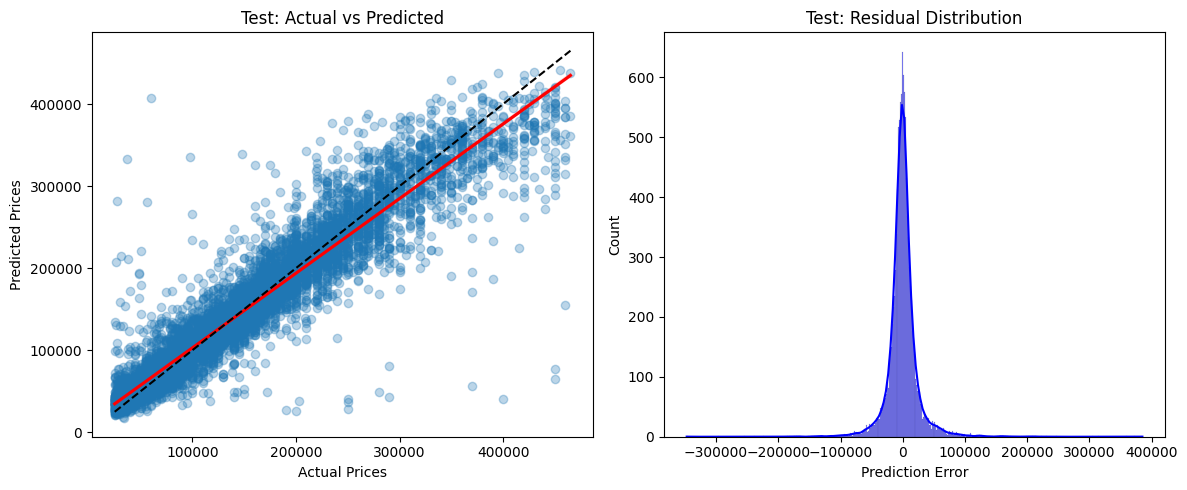


=== Performance Summary ===
                Model            MSE      RMSE       MAE     R²
LightGBM (Validation) 650,223,593.96 25,499.48 14,962.06 0.9111
      LightGBM (Test) 666,973,684.59 25,825.83 14,943.63 0.9068


In [17]:
# Evaluate on both sets
val_metrics = evaluate(model, X_val, y_val, "Validation")
test_metrics = evaluate(model, X_test, y_test, "Test")

# Display metrics summary
results_df = pd.DataFrame([val_metrics, test_metrics])
print("\n=== Performance Summary ===")
print(results_df.to_string(index=False))


In [18]:
# Save model
joblib.dump(model, 'lightgbm_model.pkl')
print("\nModel saved as 'lightgbm_model.pkl'")



Model saved as 'lightgbm_model.pkl'


In [19]:
# Model Loading & Prediction
# --------------------------
def load_model(model_path):
    """Load saved model from file"""
    try:
        return joblib.load(model_path)
    except Exception as e:
        print(f"Error loading model: {str(e)}")
        return None

In [20]:
def predict_price(user_input, model_path='lightgbm_model.pkl'):
    """Predict car price using saved LightGBM model"""
    # Load model
    model = load_model(model_path)
    if model is None:
        return None

    # Process input
    processed = {
        'year': float(user_input['year']),
        'type_boit': user_input['type_boit'].title(),
        'type_carburant': user_input['type_carburant'].title(),
        'kilometrage': float(str(user_input['kilometrage']).replace(' ', '')),
        'marke': user_input['marke'].title(),
        'model': user_input['model'].title(),
        'puissance': float(user_input['puissance']),
        'premiere_main': user_input['premiere_main'].title(),
        'Nombre_doors': int(user_input['Nombre_doors']),
        'city': user_input['city'].title(),
    }

    # Create DataFrame
    input_df = pd.DataFrame([processed])

    # Make prediction
    try:
        prediction = model.predict(input_df)[0]
        return round(prediction, 2)
    except Exception as e:
        print(f"Prediction error: {str(e)}")
        return None



In [21]:
# Example Usage
if __name__ == "__main__":
    sample_input = {
        'year': '2021',
        'type_boit': 'manuelle',
        'type_carburant': 'diesel',
        'kilometrage': '45 000',
        'marke': 'renault',
        'model': 'clio',
        'puissance': '6',
        'premiere_main': 'non',
        'Nombre_doors': '5',
        'city': 'casablanca'
    }

    print("\nSample Prediction:")
    predicted_price = predict_price(sample_input)
    if predicted_price is not None:
        print(f"Predicted Price: {predicted_price:,.2f} DH")
    else:
        print("Failed to make prediction")


Sample Prediction:
Predicted Price: 154,579.66 DH


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
